# Irrigation Prediction


### 1. Import Libraries

In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import os

### 2. Read Data

In [87]:
df = pd.read_csv('E:/Projects/AgriMind-AI/Data/Irrigation Prediction Dataset/train.csv')

### 3. Understand Data

In [88]:
df.head()

,id,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,...,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,0,Loamy,4.92,32.58,1.01,3.05,15.01,50.61,725.99,5.90,...,Sugarcane,Sowing,Zaid,Drip,Rainwater,0.82,No,112.16,East,Low
1,1,Clay,7.08,56.61,0.44,2.00,22.92,67.86,985.66,6.98,...,Wheat,Vegetative,Kharif,Rainfed,River,5.27,Yes,47.16,South,Low
2,2,Clay,5.69,27.71,0.81,2.83,26.97,92.22,2201.70,6.05,...,Rice,Vegetative,Kharif,Sprinkler,Reservoir,8.24,Yes,110.38,North,Low
3,3,Sandy,5.65,13.32,1.33,0.87,13.32,61.57,1357.33,9.12,...,Wheat,Flowering,Kharif,Canal,River,8.32,Yes,53.85,South,Medium
4,4,Clay,7.96,59.14,0.38,0.96,20.22,91.11,1538.20,6.95,...,Wheat,Sowing,Rabi,Canal,River,7.37,No,93.19,South,Low


In [89]:
df.shape

(630000, 21)

In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 630000 entries, 0 to 629999
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       630000 non-null  int64  
 1   Soil_Type                630000 non-null  str    
 2   Soil_pH                  630000 non-null  float64
 3   Soil_Moisture            630000 non-null  float64
 4   Organic_Carbon           630000 non-null  float64
 5   Electrical_Conductivity  630000 non-null  float64
 6   Temperature_C            630000 non-null  float64
 7   Humidity                 630000 non-null  float64
 8   Rainfall_mm              630000 non-null  float64
 9   Sunlight_Hours           630000 non-null  float64
 10  Wind_Speed_kmh           630000 non-null  float64
 11  Crop_Type                630000 non-null  str    
 12  Crop_Growth_Stage        630000 non-null  str    
 13  Season                   630000 non-null  str    
 14  Irrigation_Type

### 4. Data Quality Checks

In [91]:
df.isnull().sum()

id                         0
Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hours             0
Wind_Speed_kmh             0
Crop_Type                  0
Crop_Growth_Stage          0
Season                     0
Irrigation_Type            0
Water_Source               0
Field_Area_hectare         0
Mulching_Used              0
Previous_Irrigation_mm     0
Region                     0
Irrigation_Need            0
dtype: int64

In [92]:
df.duplicated().sum()

np.int64(0)

In [93]:
df['id'].duplicated().sum()

np.int64(0)

In [94]:
df['Irrigation_Need'].value_counts()

Irrigation_Need
Low       369917
Medium    239074
High       21009
Name: count, dtype: int64

#### 3.1 Target Distribution

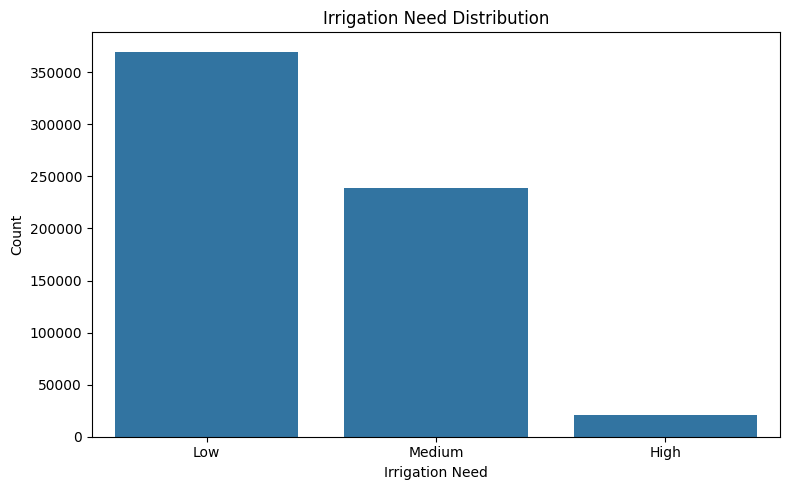

In [95]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Irrigation_Need",
    order=["Low", "Medium", "High"]
)

plt.title("Irrigation Need Distribution")
plt.xlabel("Irrigation Need")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

#### 3.2 Numerical Features Distribution

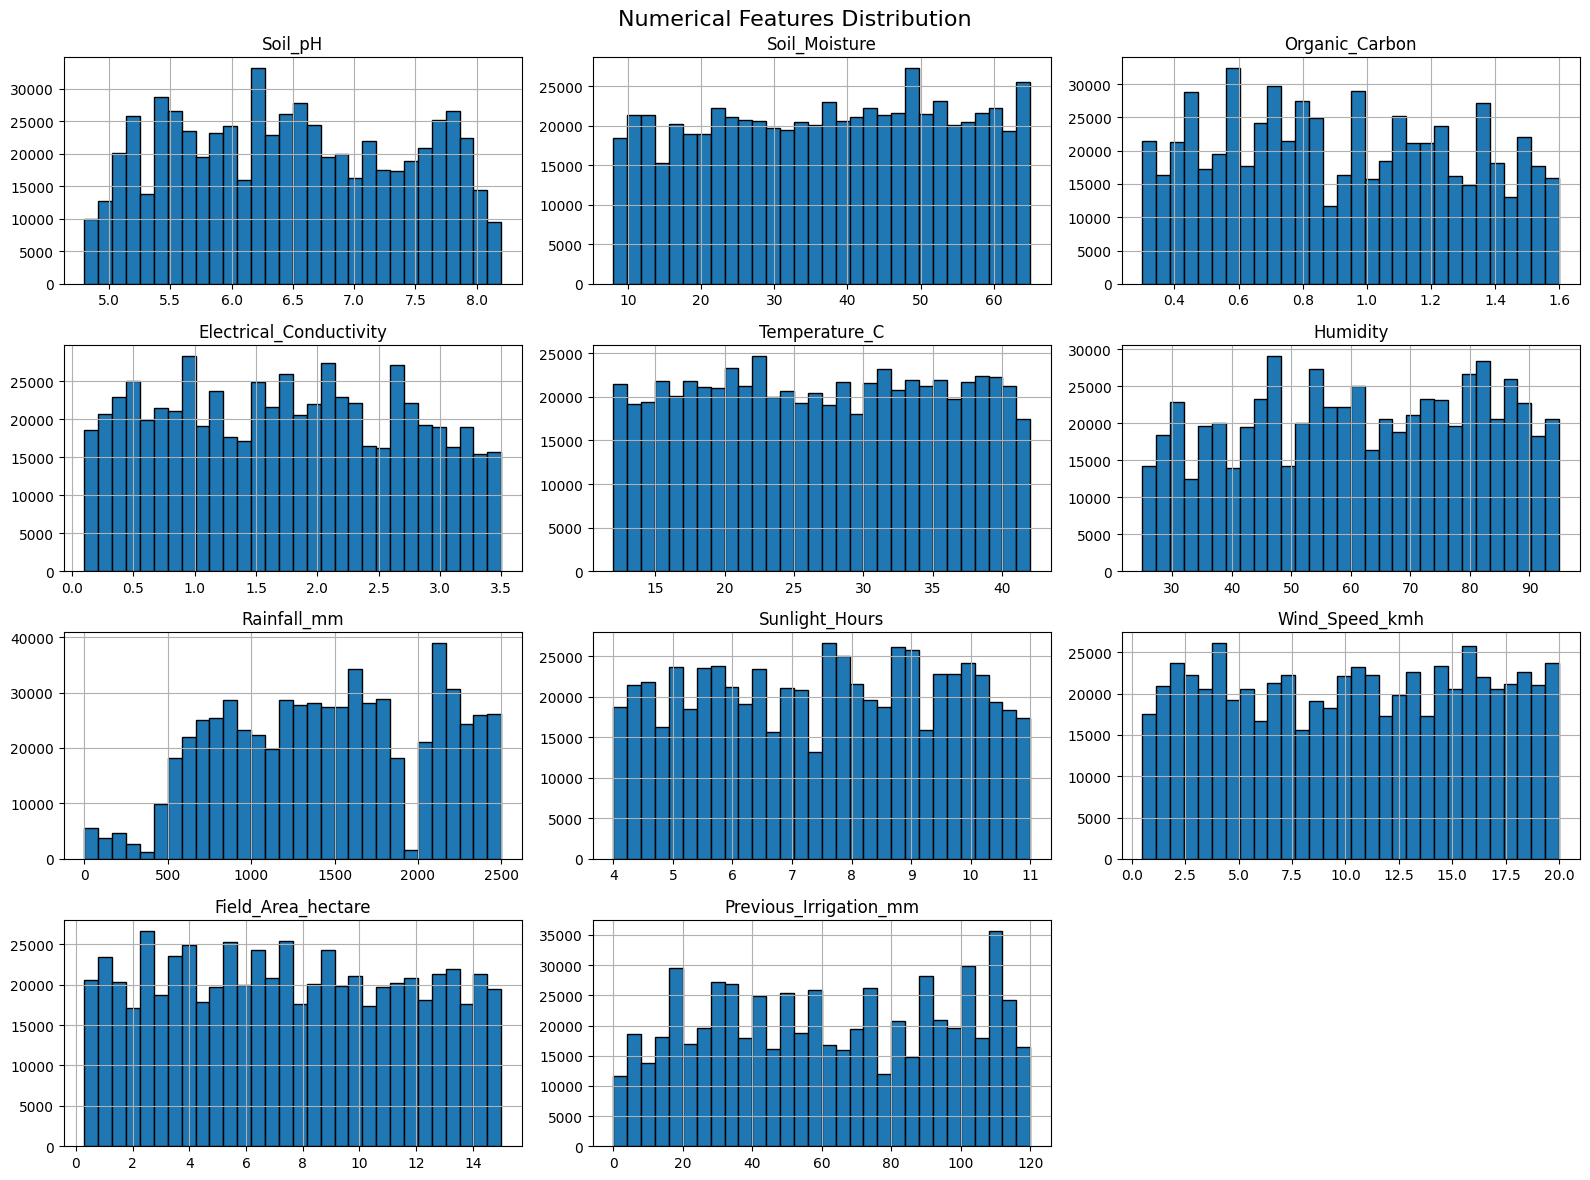

In [96]:
numerical_features = df.select_dtypes(include="number").columns.drop("id")

df[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numerical Features Distribution", fontsize=16)
plt.tight_layout()
plt.show()

### 4. Outlier Detection
#### 4.1 Detect Outliers Using IQR

In [97]:
for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    print(f"{col}: {outliers_count} outliers")

Soil_pH: 0 outliers
Soil_Moisture: 0 outliers
Organic_Carbon: 0 outliers
Electrical_Conductivity: 0 outliers
Temperature_C: 0 outliers
Humidity: 0 outliers
Rainfall_mm: 0 outliers
Sunlight_Hours: 0 outliers
Wind_Speed_kmh: 0 outliers
Field_Area_hectare: 0 outliers
Previous_Irrigation_mm: 0 outliers


## 5. Categorical Features Analysis
### 5.1 Unique Values

In [98]:
categorical_features = df.select_dtypes(
    include=["object", "str"]
).columns.drop("Irrigation_Need")

for col in categorical_features:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts())


Soil_Type: 4 unique values
Soil_Type
Sandy    166509
Clay     158470
Loamy    156455
Silt     148566
Name: count, dtype: int64

Crop_Type: 6 unique values
Crop_Type
Sugarcane    108910
Rice         106697
Cotton       104645
Maize        104274
Wheat        103005
Potato       102469
Name: count, dtype: int64

Crop_Growth_Stage: 4 unique values
Crop_Growth_Stage
Harvest       167689
Flowering     157563
Vegetative    157246
Sowing        147502
Name: count, dtype: int64

Season: 3 unique values
Season
Kharif    216561
Rabi      208033
Zaid      205406
Name: count, dtype: int64

Irrigation_Type: 4 unique values
Irrigation_Type
Canal        161901
Sprinkler    161400
Rainfed      155607
Drip         151092
Name: count, dtype: int64

Water_Source: 4 unique values
Water_Source
Reservoir      162994
River          159819
Groundwater    154155
Rainwater      153032
Name: count, dtype: int64

Mulching_Used: 2 unique values
Mulching_Used
No     316453
Yes    313547
Name: count, dtype: int64



## 6. Relationship Between Features and Irrigation Need
### 6.1 Categorical Features vs Target

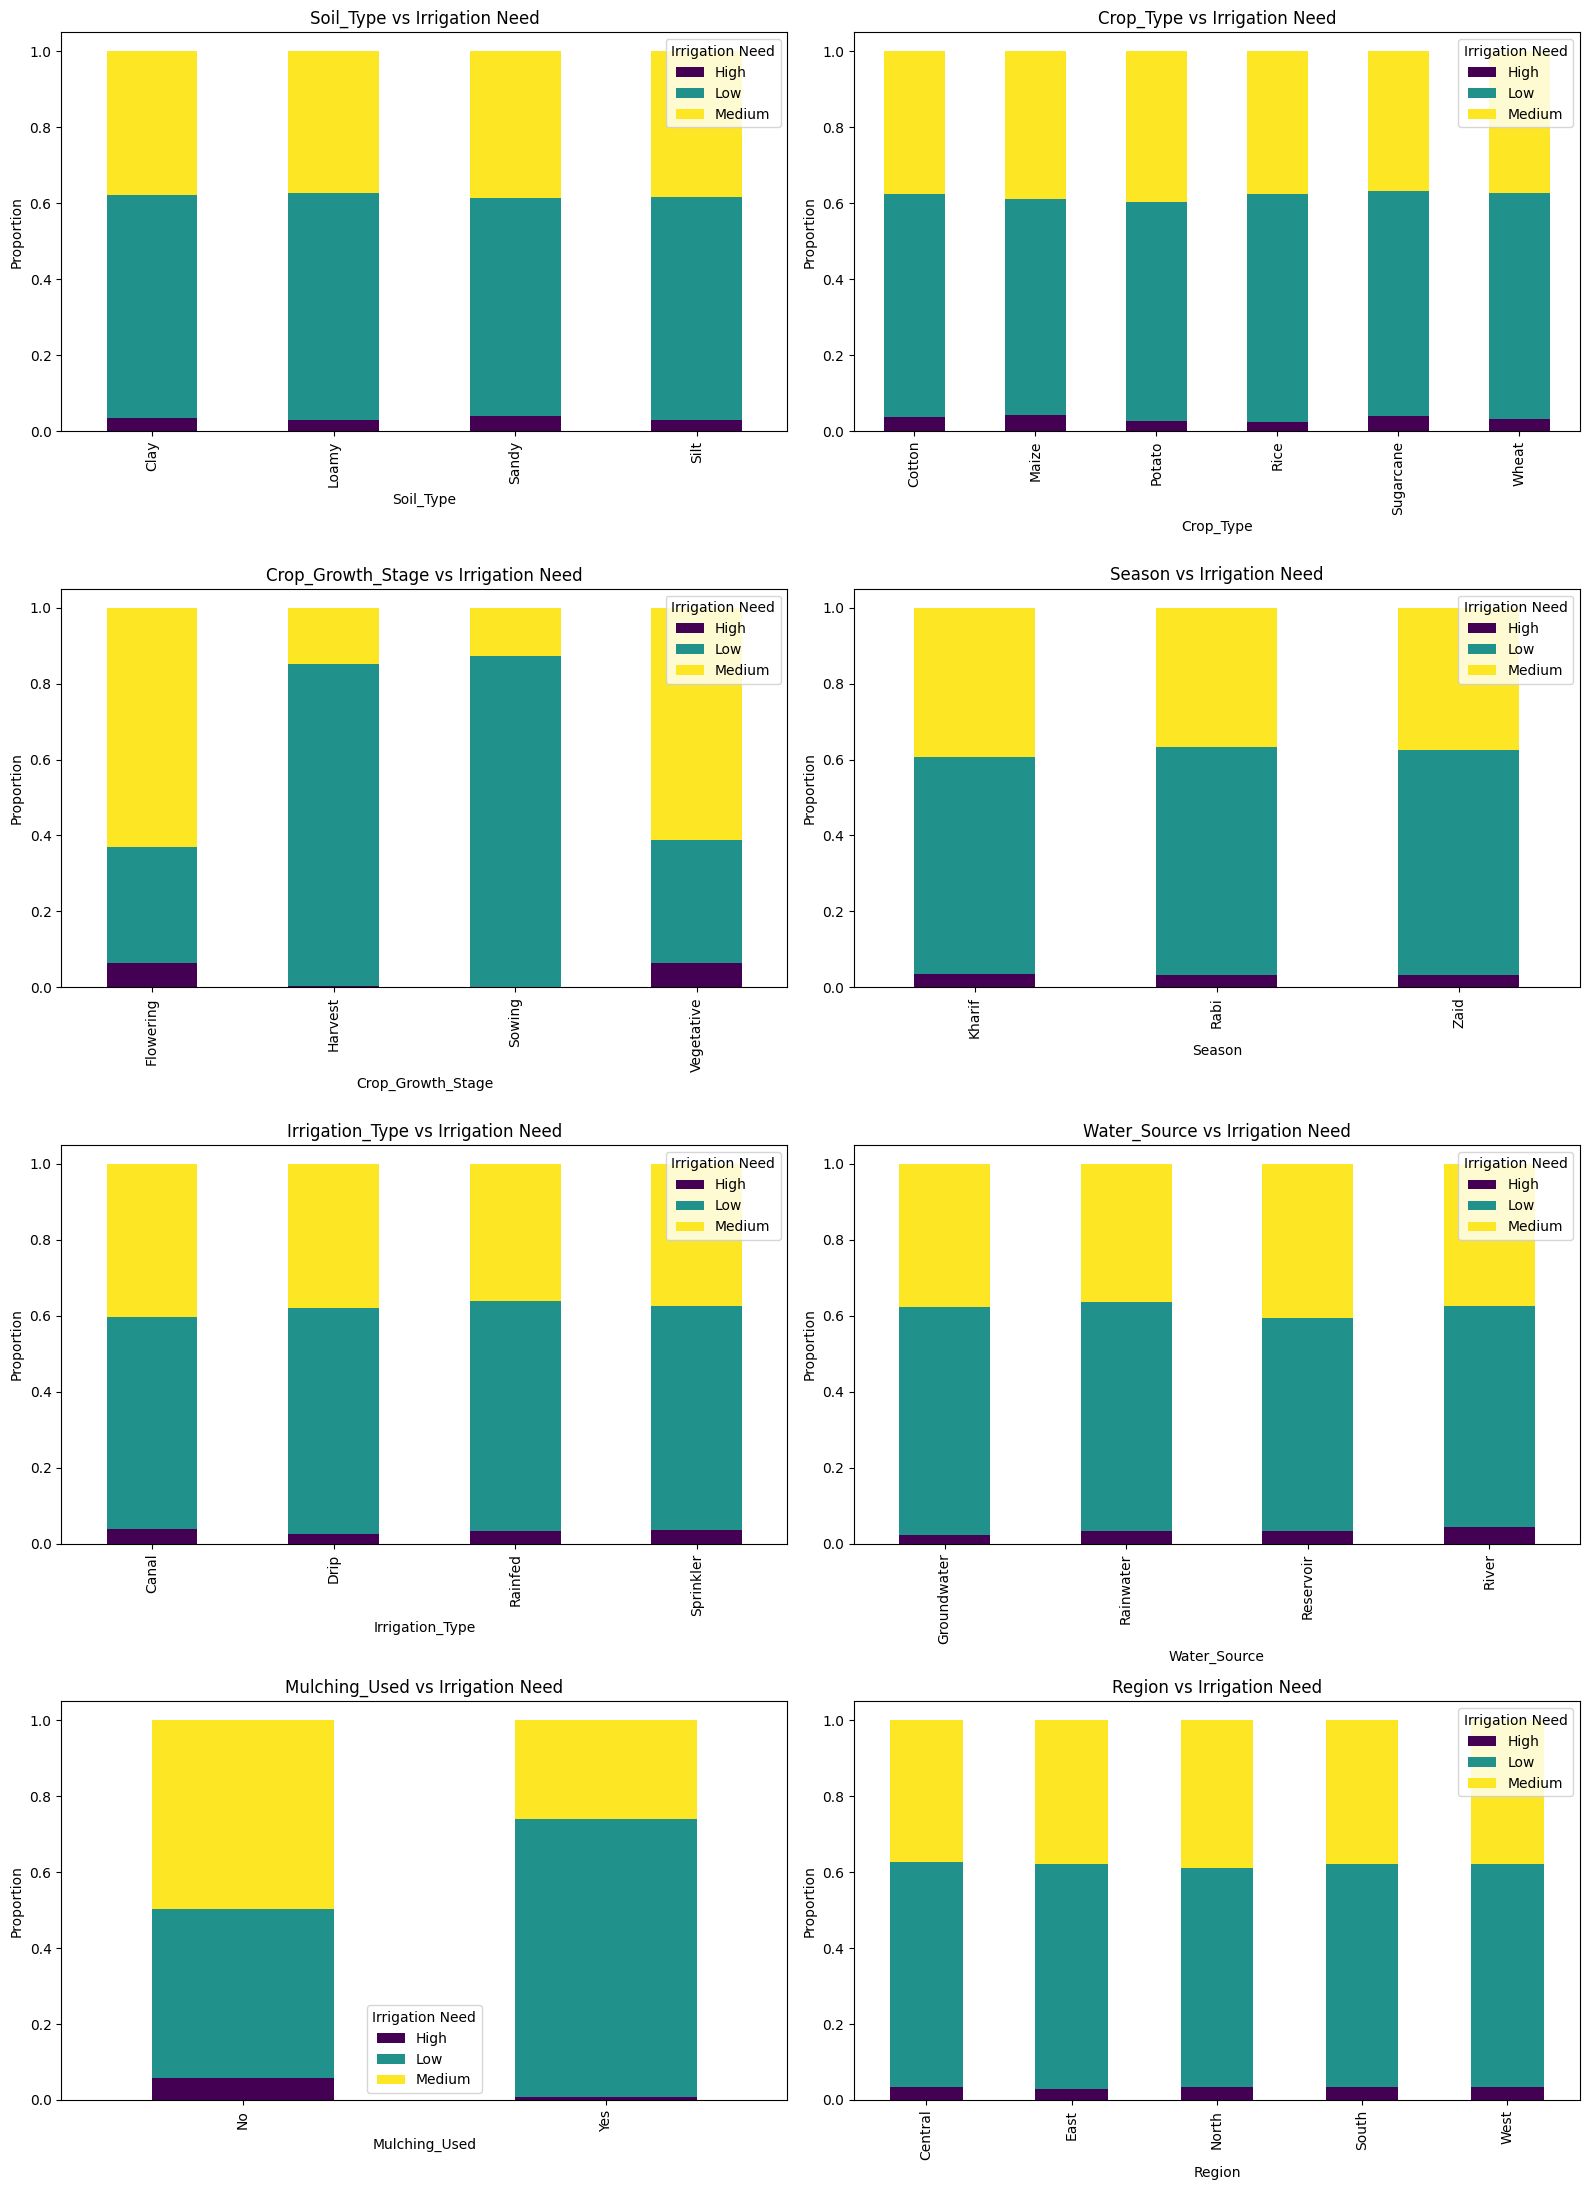

In [99]:
categorical_to_analyze = [
    "Soil_Type",
    "Crop_Type",
    "Crop_Growth_Stage",
    "Season",
    "Irrigation_Type",
    "Water_Source",
    "Mulching_Used",
    "Region"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 22))
axes = axes.flatten()

for i, col in enumerate(categorical_to_analyze):
    cross_tab = pd.crosstab(
        df[col],
        df["Irrigation_Need"],
        normalize="index"
    )

    cross_tab.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        colormap="viridis"
    )

    axes[i].set_title(f"{col} vs Irrigation Need")
    axes[i].set_ylabel("Proportion")
    axes[i].set_xlabel(col)
    axes[i].legend(title="Irrigation Need")

plt.tight_layout()
plt.show()

In [100]:
numerical_features = df.select_dtypes(include="number").columns.drop("id")

df.groupby("Irrigation_Need")[numerical_features].mean().T

Irrigation_Need,High,Low,Medium
Soil_pH,6.578282,6.487805,6.465867
Soil_Moisture,17.669875,43.305902,29.743961
Organic_Carbon,0.924143,0.920680,0.926116
Electrical_Conductivity,1.690880,1.731755,1.769208
Temperature_C,34.568134,25.347708,28.886683
Humidity,61.119576,61.949194,61.004887
Rainfall_mm,989.156678,1500.534313,1444.475028
Sunlight_Hours,7.463138,7.511125,7.521290
Wind_Speed_kmh,14.642639,9.216424,11.793668
Field_Area_hectare,7.530391,7.447241,7.625725


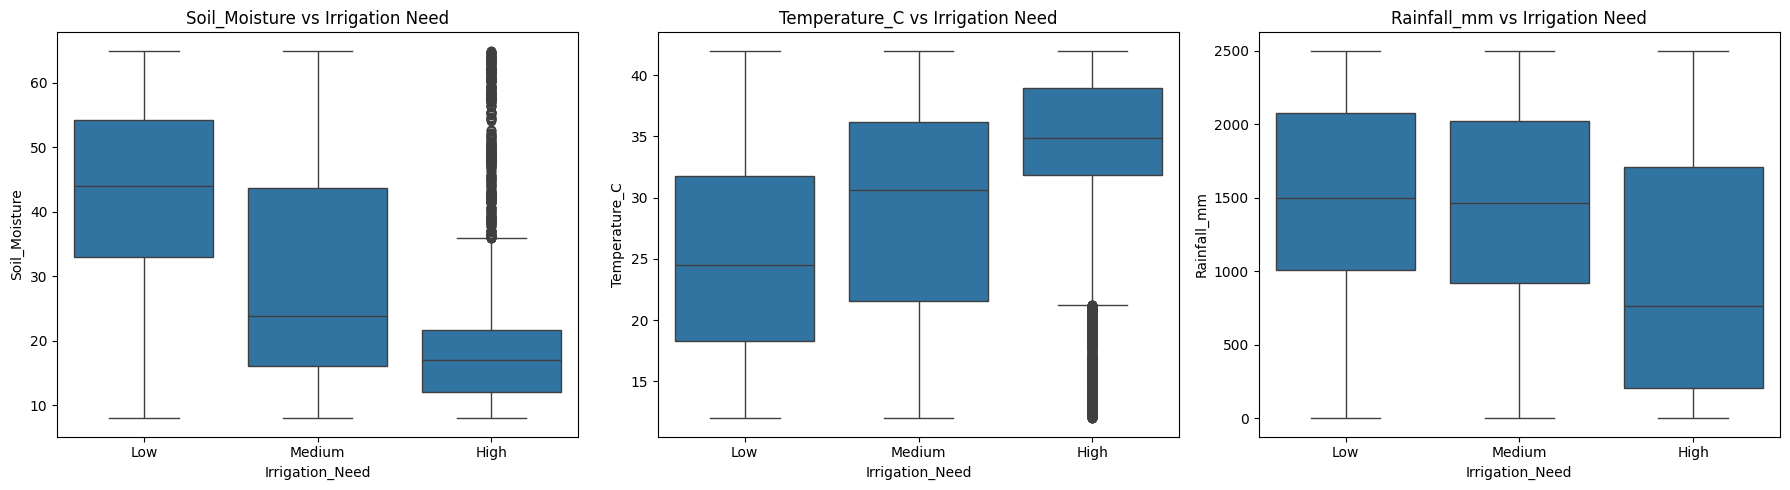

In [101]:
features = [
    "Soil_Moisture",
    "Temperature_C",
    "Rainfall_mm"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, features):
    sns.boxplot(
        data=df,
        x="Irrigation_Need",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} vs Irrigation Need")

plt.tight_layout()
plt.show()

In [102]:
features = ["Soil_Moisture", "Temperature_C"]

for col in features:
    print(f"\n{col}")

    for label in df["Irrigation_Need"].unique():
        values = df.loc[df["Irrigation_Need"] == label, col]

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = ((values < lower) | (values > upper)).sum()

        print(f"{label}: {outliers} outliers")


Soil_Moisture
Low: 0 outliers
Medium: 0 outliers
High: 511 outliers

Temperature_C
Low: 0 outliers
Medium: 0 outliers
High: 940 outliers


In [103]:
for col in ["Soil_Moisture", "Temperature_C"]:
    values = df.loc[df["Irrigation_Need"] == "High", col]

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    print(f"\n{col}")
    print("Min:", values.min())
    print("Max:", values.max())
    print("Lower Bound:", Q1 - 1.5 * IQR)
    print("Upper Bound:", Q3 + 1.5 * IQR)


Soil_Moisture
Min: 8.01
Max: 64.99
Lower Bound: -2.155000000000001
Upper Bound: 35.965

Temperature_C
Min: 12.02
Max: 41.99
Lower Bound: 21.240000000000002
Upper Bound: 49.559999999999995


### 7. Data Preparation for Machine Learning

In [104]:
df = df.drop(columns=["id"])


X = df.drop(columns=["Irrigation_Need"])
y = df["Irrigation_Need"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True) * 100)

Features shape: (630000, 19)
Target shape: (630000,)

Target distribution:
Irrigation_Need
Low       58.716984
Medium    37.948254
High       3.334762
Name: proportion, dtype: float64


#### 7.1 Train-Test Split

In [105]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (504000, 19)
X_test: (126000, 19)
y_train: (504000,)
y_test: (126000,)


### 7.2 Identifying Numerical and Categorical Features### 5.2 Identifying Numerical and Categorical Features

In [106]:
numerical_features = X_train.select_dtypes(include="number").columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nNumber of Numerical Features:", len(numerical_features))

print("\nCategorical Features:", categorical_features)
print("\nNumber of Categorical Features:", len(categorical_features))

Numerical Features: ['Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Field_Area_hectare', 'Previous_Irrigation_mm']

Number of Numerical Features: 11

Categorical Features: ['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region']

Number of Categorical Features: 8


#### 7.3 Building the Preprocessing Pipeline

In [107]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

#### 7.4 Building the Machine Learning Pipeline

In [108]:

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

#### 7.5 Model Training

In [109]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['Soil_Type','Soil_pH','Soil_Moisture',...,'Mulching_Used', 'Previous_Irrigation_mm','Region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

### 7.6 Model Evaluation

Accuracy: 0.9857380952380952

Classification Report:

              precision    recall  f1-score   support

        High       0.96      0.92      0.94      4202
         Low       0.99      1.00      0.99     73983
      Medium       0.99      0.98      0.98     47815

    accuracy                           0.99    126000
   macro avg       0.98      0.96      0.97    126000
weighted avg       0.99      0.99      0.99    126000



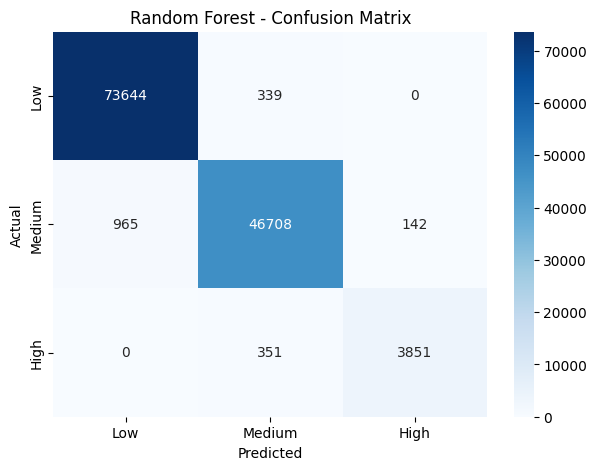

In [111]:
y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion 
cm = confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

#### 7.7 Model Evaluation Summary

The Random Forest classifier achieved an accuracy of **98.57%** on the test set.

The model performed well across all three irrigation need classes. It achieved an F1-score of **0.94** for the High class, despite its relatively small representation in the dataset. The macro-average F1-score of **0.97** also indicates strong overall performance across classes.

These results are promising, but further validation is needed to confirm that the model generalizes well to unseen real-world data.

#### 7.8 Feature Importance Analysis

In [112]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importances = rf_model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Display top 15 features
feature_importance.head(15)

,Feature,Importance
33,remainder__Soil_Moisture,0.264269
36,remainder__Temperature_C,0.133038
38,remainder__Rainfall_mm,0.103866
40,remainder__Wind_Speed_kmh,0.103530
11,categorical__Crop_Growth_Stage_Harvest,0.058837
12,categorical__Crop_Growth_Stage_Sowing,0.057138
25,categorical__Mulching_Used_No,0.048861
26,categorical__Mulching_Used_Yes,0.045268
13,categorical__Crop_Growth_Stage_Vegetative,0.041995
10,categorical__Crop_Growth_Stage_Flowering,0.039284


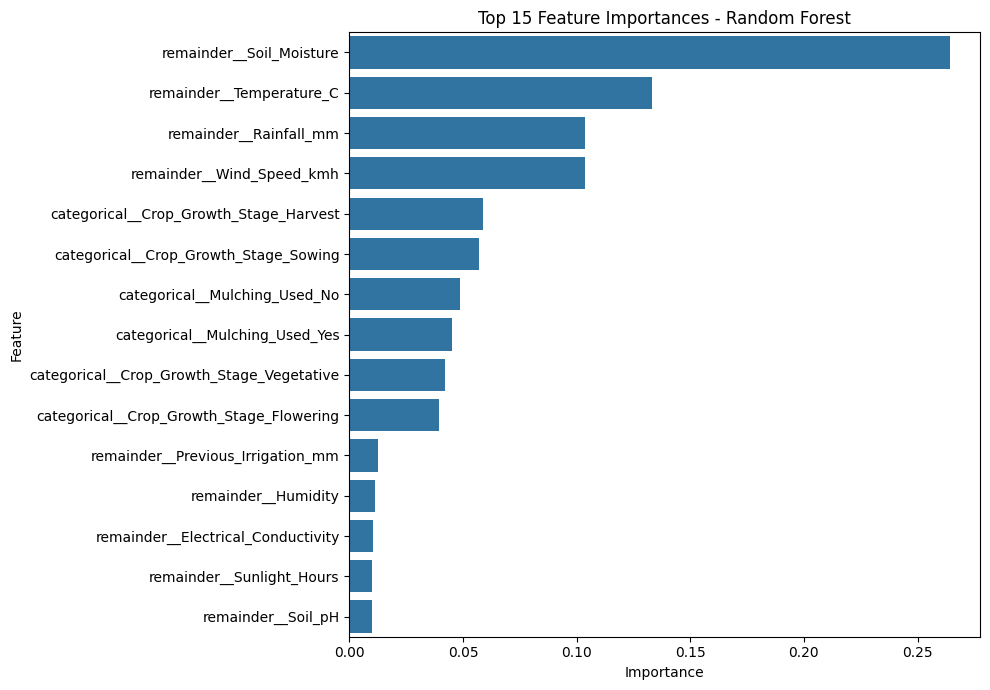

In [113]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

#### 7.9 Feature Distribution Across Irrigation Classes

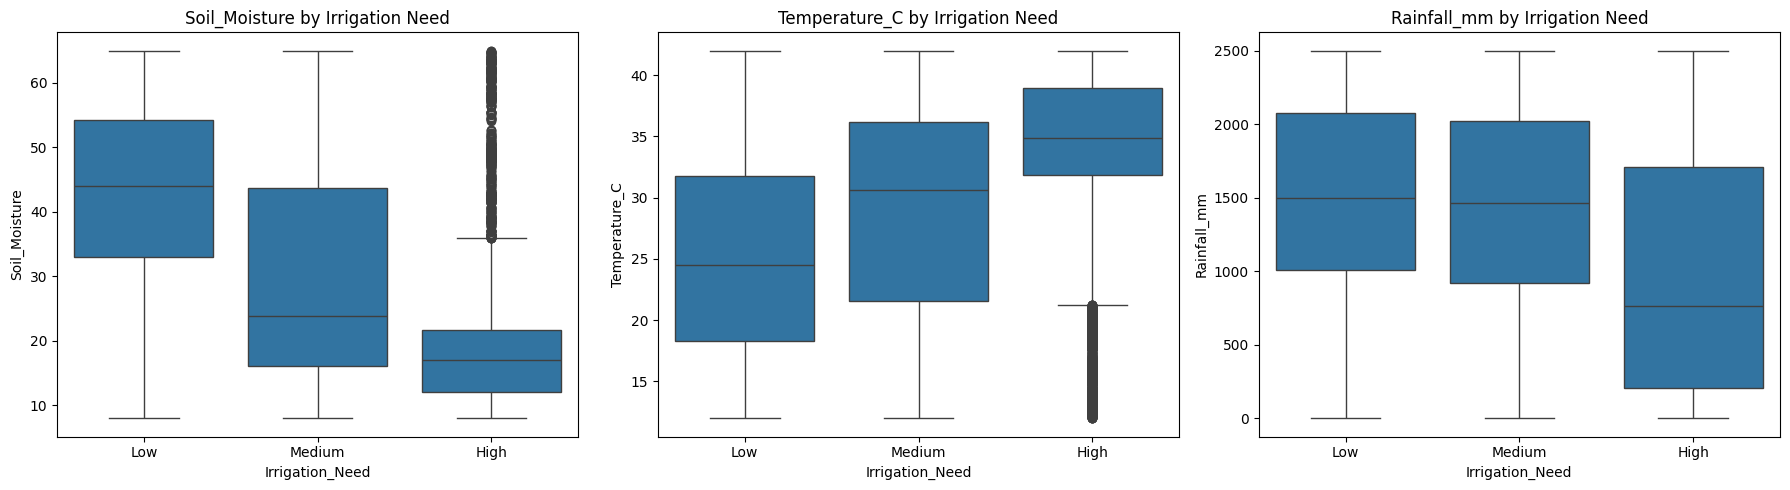

In [114]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = [
    "Soil_Moisture",
    "Temperature_C",
    "Rainfall_mm"
]

for ax, col in zip(axes, features):
    sns.boxplot(
        data=df,
        x="Irrigation_Need",
        y=col,
        order=["Low", "Medium", "High"],
        ax=ax
    )
    ax.set_title(f"{col} by Irrigation Need")

plt.tight_layout()
plt.show()

#### 7.10 Saving the Trained Model

In [116]:
os.makedirs("../Models", exist_ok=True)

joblib.dump(
    rf_model,
    "../Models/irrigation_prediction_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [117]:
loaded_model = joblib.load(
    "../Models/irrigation_prediction_model.pkl"
)

sample = X_test.iloc[[0]]

print("Actual:", y_test.iloc[0])
print("Predicted:", loaded_model.predict(sample)[0])

Actual: Low
Predicted: Low


### 8. Conclusion

### Irrigation Prediction — Project Summary

In this project, we developed a machine learning model to predict irrigation needs using soil, weather, crop, and field-related features.

**Key Steps:**
- Explored a dataset containing 630,000 records and 21 columns.
- Checked missing values, duplicate records, feature distributions, and potential outliers.
- Split the data into training and testing sets using stratified sampling.
- Built a preprocessing pipeline using One-Hot Encoding for categorical features.
- Trained a Random Forest classifier with balanced class weights.
- Evaluated the model using accuracy, precision, recall, F1-score, and a confusion matrix.

**Results:**
- Test Accuracy: 98.57%
- Macro-average F1-score: 0.97
- High-class Recall: 0.92

Soil moisture, temperature, rainfall, and wind speed were among the most important features according to the model.

The trained pipeline was saved for future use and successfully loaded to generate predictions.

Further validation on independent, real-world data is recommended before deployment.